# Adaptive Destroy-and-Repair VNS with Q-Learning Operator Selection for Multi-Compartment Routing with Reconfigurable Vehicles
**ISE 571 Heuristic Search Methods, KFUPM. Term Project, Group 6:** Maha Abd Elhakeem, Sadia Waseem, Saphiah Bajba
Code: https://github.com/SadiaWaseem/571-Project

This notebook reproduces every result of our IEEE paper. All algorithms live in the `mvrdc/` package of the repository; the notebook only calls them. The results of the long experiments (900 + 144 runs) are stored in `results/main` and `results/sens` and are analysed here; the cells that produced them are included and can be re-run.

| Section | Content |
|---|---|
| 0 | Setup (Colab or local) |
| 1 | The MVRDC problem and benchmark of Masmoudi et al. (2026) [1], with an instance gallery and a time-window schedule |
| 2 | Validation of our implementation against the published solutions |
| 3 | Methods compared |
| 4 | One instance, step by step |
| 5 | Experiment 1: learned *neighborhood* selection (diagnosis) |
| 6 | Experiment 2 (main): learned *operator* selection, with a visual analysis (heat map, performance profile, critical-difference diagram, radar, solution anatomy, learning dynamics) |
| 7 | Parameter sensitivity of the Q-learning policy |
| 8 | Small instances: comparison with the CPLEX optima of [1] |
| 9 | Interactive explorer of all 900 solutions |
| 10 | Pros and cons |

The long experiments are switched off by default (`RUN_... = False`); Sections 6–7 then analyse the stored results. When re-run, they write one file per run, so an interrupted session resumes where it stopped.

## 0. Setup

In [1]:
import os, sys
REPO_URL = "https://github.com/SadiaWaseem/571-Project.git"
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not os.path.exists("/content/571-Project"):
        !git clone -q $REPO_URL /content/571-Project
    %cd /content/571-Project
    !pip -q install -r requirements.txt
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
if not os.path.isdir("data/MVRDC/Instances"):
    !bash scripts/fetch_data.sh
sys.path.insert(0, os.getcwd())
DATA = "data/MVRDC"
print("working directory:", os.getcwd())

working directory: /home/claude/mvrdc-qvns


Keep results on Google Drive (recommended for the long experiments) so that they survive a disconnected session.

In [2]:
USE_DRIVE = False
RESULTS_ROOT = "results"
if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    RESULTS_ROOT = "/content/drive/MyDrive/ISE571-QVNS/results"
os.makedirs(RESULTS_ROOT, exist_ok=True)
print("results are written to", RESULTS_ROOT)

results are written to results


In [3]:
import glob, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from mvrdc.instance import load_instance, list_instances
from mvrdc.selectors import make_selector, OPS_ALGORITHMS
from mvrdc.operators import operator_shaking, OP_NAMES
from mvrdc.vns import VNSConfig, solve
from mvrdc.solution import Evaluator
from mvrdc import analysis as A, plots as P, visuals as Vz
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "font.size": 8})

def run(inst, alg, seconds, seed=1):
    # one run of any method; operator-selection methods use the destroy-and-repair portfolio
    if alg in OPS_ALGORITHMS:
        with operator_shaking():
            return solve(inst, make_selector(alg), VNSConfig(time_limit=seconds), seed)
    return solve(inst, make_selector(alg), VNSConfig(time_limit=seconds), seed)

def results_dir(*candidates):
    # first folder that holds results (runs/ or runs.zip); the repository ships results/main and results/sens
    ok = lambda d: os.path.isdir(f"{d}/runs") or os.path.exists(f"{d}/runs.zip")
    d = next(c for c in candidates if ok(c))
    print("results from:", d)
    return d

## 1. Problem and data
The MVRDC [1] serves $n$ customers with fresh demand $q^1_i$, frozen demand $q^2_i$ and time window $[e_i,l_i]$ from one depot. The fleet has fresh and frozen single-temperature vehicles, which may carry the other product in frigoboxes of capacity $w$ (at most $F_k$ per vehicle and $F$ at the depot), and mixed-reconfigurable vehicles with $m_k$ predefined fresh/frozen splits. The objective is lexicographic:
$$f(x)=1000\,\#\text{vehicles}+\text{distance}+\theta\,\text{unused space},\qquad \theta=1/\textstyle\sum_i(q^1_i+q^2_i).$$
The benchmark has 15 instances each with 10, 15 and 20 customers, and 60 instances with 200 customers in three fleet classes: A0 (vehicle capacity 150–250), A1 (650–750) and A2 (950–1050).

In [4]:
rows = [load_instance(p).summary() for size in ["10 customers", "15 customers", "20 customers", "200 customers"]
        for p in list_instances(DATA, size)]
inst_table = pd.DataFrame(rows)
inst_table["class"] = inst_table["name"].str.extract(r"^(A\d)")
inst_table.groupby(["customers", "class"]).agg(
    instances=("name", "size"), fresh_units=("fresh_units", "mean"), frozen_units=("frozen_units", "mean"),
    mixed_units=("mixed_units", "mean"), frigoboxes=("frigoboxes", "mean"),
    fresh_demand=("fresh_demand", "mean"), frozen_demand=("frozen_demand", "mean")).round(1)

instances  fresh_units  frozen_units  mixed_units  frigoboxes  fresh_demand  frozen_demand
customers class                                                                                            
10        A0            15          2.0           2.0          2.0        10.0         102.7          119.5
15        A0            15          3.0           3.0          3.0        15.0         150.5          147.3
17        A0            10          3.0           2.9          3.0        15.0         198.6          214.1
18        A0             1          3.0           3.0          3.0        15.0         172.0          220.0
20        A0             4          3.0           3.0          3.0        15.0         178.2          244.0
200       A0            30         17.0          19.0         17.0        50.0        2069.1         2111.8
          A1            10         17.0          18.8         17.0        50.0        2144.5         2092.6
          A2            20         17.0          17.0         17.0        50.0        2126.0         2120.8

**Three fleet classes, one map each.** Every dot is a customer; its colour is the frozen share of its demand and its size the total demand. In A0 the customers are clustered and the vehicles small (150–250 units), so a solution needs about 25 routes; in A1/A2 the vehicles are three to five times larger and about 6 routes suffice. This difference turns out to decide which selection policy works best (Section 6).

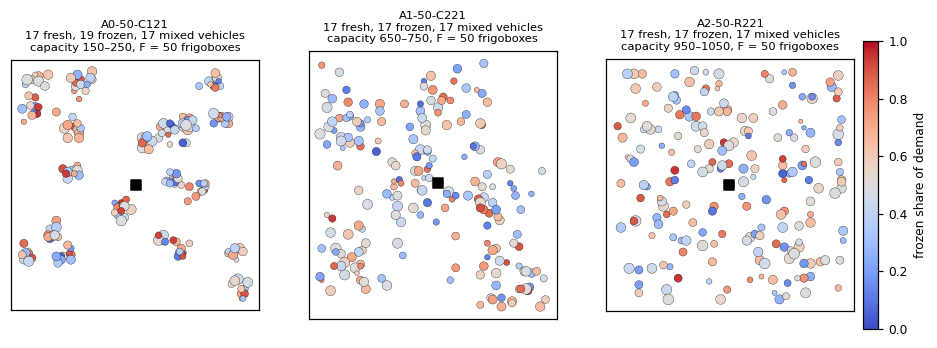

In [5]:
gallery = [load_instance(f"{DATA}/Instances/200 customers/{n}.txt") for n in ["A0-50-C121", "A1-50-C221", "A2-50-R221"]]
Vz.plot_instance_gallery(gallery); plt.show()
inst = gallery[0]

**Why time windows make this hard.** The chart below is the schedule of one route of our best solution for A0-50-C121. Each grey bar is a customer's time window, in which service must *start*; red is the service itself (90 time units), and black dots are arrivals. The route is packed end to end: moving or swapping a single customer shifts every later arrival, which almost always pushes someone outside their window. This is why the swap and relocate neighborhoods of [1] fail so often (Section 5).

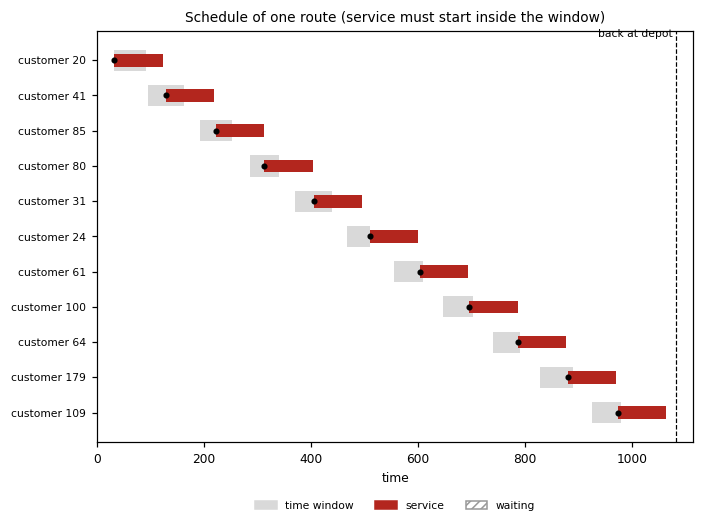

In [6]:
demo_run = A.load_runs("results/main", "A0-50-C121__ops-q__1")[0]
demo_sol = Vz.solution_from_run(inst, demo_run)
Vz.plot_tw_gantt(inst, max(demo_sol.routes, key=len)); plt.show()

## 2. Validation against the published results
For every published route solution whose instance file is also published, we audit feasibility independently (time windows, $T_{max}$, capacities, frigoboxes, one route per physical vehicle) and recompute the objective.

In [7]:
refs = A.published_references(DATA)
refs["diff"] = refs["ref_cost"] - refs["ref_reported"]
print(f"{len(refs)} published solutions checked")
print("max |recomputed - reported|:", round(float(refs["diff"].abs().max()), 3))
print("within 0.05:", int((refs["diff"].abs() <= 0.05).sum()))
refs[refs["diff"].abs() > 0.05]

74 published solutions checked
max |recomputed - reported|: 0.998
within 0.05: 73


,instance,ref_cost,ref_reported,ref_vehicles,ref_distance,diff
8,A0-10-R127,2527.822204,2528.82,2,527.433316,-0.997796


All but one agree to rounding; A0-10-R127 is reported exactly 1.0 above the cost of its own routes. Differences between the paper of [1] and its published code are documented in `docs/DEVIATIONS.md`.

## 3. Methods
All methods share the multi-start VNS of [1]: random construction, shaking, vehicle assignment (SelectBestVehicle), local search (2-opt, relocate, 2-opt*, remove-two-insert-one) and Cauchy annealing acceptance $\beta<T^2/(T^2+\Delta E^2)$. **They differ only in the shaking step.** Every per-step policy gets 20 shaking steps per restart, the nominal budget of the sweep of [1].

**Experiment 1: which neighborhood?** Actions $N_1$ swap, $N_2$ relocate, $N_3$ segment shift, $N_4$ remove-insert.

| label | policy |
|---|---|
| `ms-vns` | [1]: sweep $N_1\to N_4$, 5 attempts each; order re-sorted every 100 restarts by scores (1, 0, 5) |
| `vns-random` | uniform random neighborhood |
| `q-vns` | tabular Q-learning over the 4 neighborhoods |
| `vns-n4` | $N_4$ only |

**Experiment 2: which destroy-and-repair operator?** Every shaking step is a remove–insert move. The action is one of 8 pairs (removal $\in$ {random, worst, related, route}) × (insertion $\in$ {greedy, regret-2}).

| label | policy |
|---|---|
| `ops-random` | uniform random pair |
| `ops-alns` | ALNS roulette wheel (Ropke & Pisinger 2006): scores (33, 9, 13), reaction 0.1, segments of 100 steps |
| `ops-q` | **ours**: tabular Q-learning; state = (last outcome, stagnation, search phase), 27 states × 8 actions |

**Q-learning.** Rewards are 5 / 2 / 0.5 / 0 / −1 for new best / improved / accepted / rejected / infeasible. The update is $Q(s,a)\leftarrow Q(s,a)+\alpha\,[r+\gamma\max_{a'}Q(s',a')-Q(s,a)]$, with the last step of a restart treated as terminal, $\alpha=0.1$, $\gamma=0.9$, and $\varepsilon$-greedy exploration with $\varepsilon$ decaying linearly from 0.3 to 0.05 over the time budget.

## 4. One instance, step by step
The baseline of [1] and our method on A0-50-C121, 30 s each.

ms-vns  cost= 36866.11  vehicles=32  distance= 4865.6  gap to [1]=  8.45%  feasible=True
ops-q   cost= 29203.12  vehicles=25  distance= 4202.8  gap to [1]=-14.09%  feasible=True
published solution of [1]: 33994.51


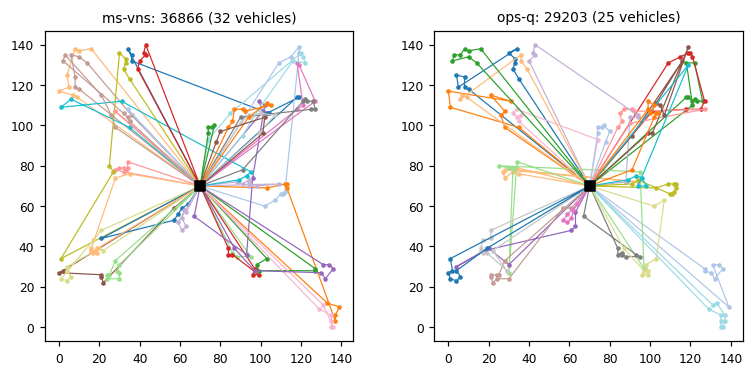

In [8]:
demo = {alg: run(inst, alg, 30) for alg in ["ms-vns", "ops-q"]}
ref = refs.set_index("instance").loc[inst.name, "ref_cost"]
for alg, r in demo.items():
    print(f"{alg:7s} cost={r.best_cost:9.2f}  vehicles={r.vehicles}  distance={r.distance:7.1f}  "
          f"gap to [1]={100 * (r.best_cost - ref) / ref:6.2f}%  feasible={r.feasible}")
print(f"published solution of [1]: {ref:.2f}")
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.4))
for ax, (alg, r) in zip(axes, demo.items()):
    P.plot_routes(inst, r.routes, ax=ax, title=f"{alg}: {r.best_cost:.0f} ({r.vehicles} vehicles)")
plt.tight_layout(); plt.show()

## 5. Experiment 1: learned neighborhood selection (diagnosis)
Pilot: 6 instances (one per family), 3 seeds, 30 s. To rerun it:
`python experiments/run.py --data data/MVRDC --instances A0-50-C121 A0-50-R121 A0-50-RC121 A1-50-C221 A2-50-R221 A2-50-RC221 --algorithms ms-vns vns-random q-vns vns-n4 --seeds 1-3 --time-limit 30 --workers 2 --out results/pilot`

In [9]:
res1 = A.add_gaps(A.load_results("results/pilot"), refs)
res1 = res1[res1["algorithm"].isin(["ms-vns", "vns-random", "q-vns", "vns-n4"])]
display(A.summary_table(res1)[["algorithm", "instances", "best_gap", "avg_gap", "vehicles", "restarts"]])
use1 = A.neighborhood_usage(A.load_runs("results/pilot"))
use1 = use1[use1["algorithm"].isin(["ms-vns", "q-vns"])]
u = use1.groupby(["algorithm", "neighborhood"])[["picks", "infeasible"]].sum()
u["share"] = use1.groupby(["algorithm", "neighborhood"])["share"].mean().round(3)
u["infeasible_%"] = (100 * u["infeasible"] / u["picks"]).round(1)
u[["share", "infeasible_%"]].unstack(0)

,algorithm,instances,best_gap,avg_gap,vehicles,restarts
0,ms-vns,6,2.497,4.949,19.556,250.278
3,vns-random,6,2.173,3.865,19.278,252.111
1,q-vns,6,-4.657,-2.754,18.389,142.556
2,vns-n4,6,-5.355,-4.137,18.222,83.667


share        infeasible_%      
algorithm    ms-vns  q-vns       ms-vns q-vns
neighborhood                                 
N1            0.248  0.055         81.1  76.2
N2            0.249  0.087         56.1  48.9
N3            0.249  0.294         26.7  10.1
N4            0.254  0.564          0.1   0.6

**Reading.** Under the sweep of [1], most $N_1$ (swap) and about half of $N_2$ (relocate) shakes find no feasible move on these tight time windows, yet each neighborhood keeps a quarter of the budget. Re-ordering cannot change that allocation. Q-learning moves effort to $N_3$/$N_4$ and beats [1]'s policy, but simply applying $N_4$ does better still. A neighborhood-level agent has little to decide, which motivates Experiment 2.

## 6. Experiment 2 (main): learned destroy-and-repair operator selection
**Design.** 30 of the 60 instances with 200 customers (every second file: 15 A0, 5 A1, 10 A2), 6 methods, 5 seeds, 60 s per run, giving 900 runs.

**How the stored results were produced.** The command in the next cell was run from a terminal on an Apple MacBook Pro (4 performance cores, Python 3.9) with `--workers 3` (5.5 h); each run's 60 s budget is measured on a clock that excludes sleep. All 900 solutions were re-checked by an independent feasibility checker. To re-run on Colab (about 7.5 h on 2 cores), set `USE_DRIVE = True` in Section 0 and `RUN_MAIN = True` here.

In [10]:
RUN_MAIN = False
MAIN_DIR = f"{RESULTS_ROOT}/main"
if RUN_MAIN:
    !python experiments/run.py --data $DATA --sizes "200 customers" --every 2 \
        --algorithms ms-vns q-vns vns-n4 ops-random ops-alns ops-q --seeds 1-5 \
        --time-limit 60 --workers 2 --out "$MAIN_DIR"

In [11]:
RES2 = results_dir(MAIN_DIR, "results/main", "results/opt2_pilot")
res2 = A.add_gaps(A.load_results(RES2), refs)
print(len(res2), "runs,", res2["instance"].nunique(), "instances, all feasible:", bool(res2["feasible"].all()))
A.summary_table(res2)

results from: results/main
900 runs, 30 instances, all feasible: True


,algorithm,instances,best_gap,avg_gap,sd_gap,vehicles,time_to_best,restarts,all_feasible
0,ms-vns,30,0.259,3.705,2.608,17.320,18.118,422.727,True
4,q-vns,30,-3.654,-1.289,1.797,16.760,36.601,253.520,True
5,vns-n4,30,-6.005,-3.333,1.982,16.573,32.123,139.520,True
3,ops-random,30,-14.482,-13.246,0.908,15.000,33.112,137.507,True
1,ops-alns,30,-14.858,-13.613,1.120,14.873,38.508,134.827,True
2,ops-q,30,-15.118,-12.547,2.128,14.947,30.521,135.807,True


In [12]:
A.summary_table(res2, by=["family"])[["family", "algorithm", "instances", "best_gap", "avg_gap", "vehicles"]]

,family,algorithm,instances,best_gap,avg_gap,vehicles
0,A0-C,ms-vns,5,0.695,4.697,28.28
4,A0-C,q-vns,5,-1.407,0.359,27.40
5,A0-C,vns-n4,5,-4.159,-1.384,27.12
3,A0-C,ops-random,5,-12.968,-12.031,24.16
1,A0-C,ops-alns,5,-14.783,-13.030,23.96
2,A0-C,ops-q,5,-15.633,-13.510,23.84
6,A0-R,ms-vns,5,2.029,4.321,26.12
10,A0-R,q-vns,5,-0.110,2.458,25.96
11,A0-R,vns-n4,5,-0.680,1.614,25.80
9,A0-R,ops-random,5,-10.087,-8.163,23.36


**Statistical tests.** Paired Wilcoxon signed-rank tests on per-instance mean costs, `ops-q` against each rival (Holm-corrected), and a Friedman test across all methods.

In [13]:
display(A.wins_table(res2, "ops-q"))
sig2 = A.significance(res2, "ops-q")
display(sig2.round(4))
print("Friedman:", sig2.attrs.get("friedman"))

,vs,better,equal,worse
0,ms-vns,30,0,0
1,ops-alns,10,0,20
2,ops-random,13,0,17
3,q-vns,30,0,0
4,vns-n4,30,0,0


,vs,n_instances,median_diff,mean_diff,W,p,p_holm
0,ms-vns,30,-2821.3031,-3420.3442,0.0,0.0000,0.0000
1,q-vns,30,-1960.6957,-2492.4676,0.0,0.0000,0.0000
2,vns-n4,30,-1774.8847,-2138.2450,0.0,0.0000,0.0000
3,ops-alns,30,97.8062,70.1846,162.0,0.1519,0.3038
4,ops-random,30,114.0759,-77.4026,222.0,0.8394,0.8394


Friedman: {'chi2': 131.9238095238096, 'p': 9.295021269859314e-27, 'algorithms': ['ms-vns', 'ops-alns', 'ops-q', 'ops-random', 'q-vns', 'vns-n4'], 'instances': 30}


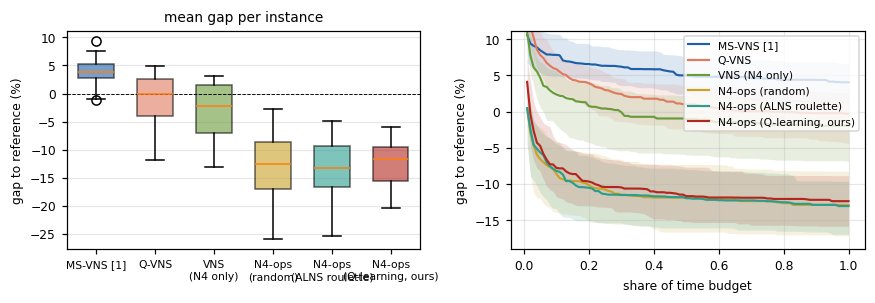

In [14]:
runs2 = A.load_runs(RES2)
conv2 = A.convergence(runs2, refs.set_index("instance")["ref_cost"].to_dict(), np.linspace(0, 1, 101))
fig, axes = plt.subplots(1, 2, figsize=(8, 2.8))
P.plot_gap_box(res2.groupby(["instance", "algorithm"], as_index=False)["gap"].mean(), ax=axes[0])
axes[0].set_title("mean gap per instance", fontsize=9)
P.plot_convergence(conv2, ax=axes[1]); axes[1].set_ylim(top=conv2[conv2.t >= 0.05]["gap"].quantile(0.99))
plt.tight_layout(); plt.show()

### 6.1 Visual overview of all 900 runs
**Heat map.** One row per instance, one column per method, colour = mean gap to [1] over 5 seeds (blue better, red worse); the best method of each row is framed. Two blocks stand out: the three operator-portfolio methods (right) are far better than the rest on every row, and among them ops-Q wins most A0 rows while ops-random/ops-ALNS win most A1/A2 rows.

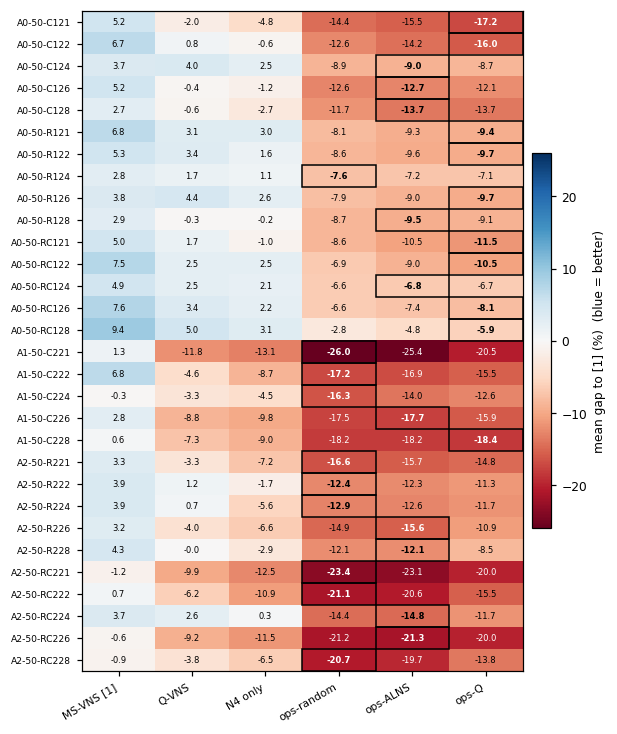

In [15]:
Vz.plot_gap_heatmap(res2); plt.show()

**Performance profile** (Dolan & Moré). For each method, the share of instances on which its mean cost is within a factor $\tau$ of the best method's cost. A curve that rises early and reaches 1 quickly is better. The portfolio methods are within 3–9% of the best method on every instance; the MS-VNS of [1] is more than 25% worse than the best on about a quarter of them.

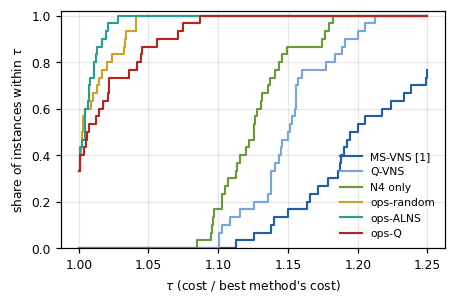

In [16]:
Vz.plot_performance_profile(res2); plt.show()

**Critical-difference diagram** (Demšar, 2006). Average rank of each method over the 30 instances (1 = best), with the Friedman/Nemenyi critical difference. Methods joined by a thick bar are not significantly different. The three portfolio methods form one group, and are separated from the neighborhood-level methods.

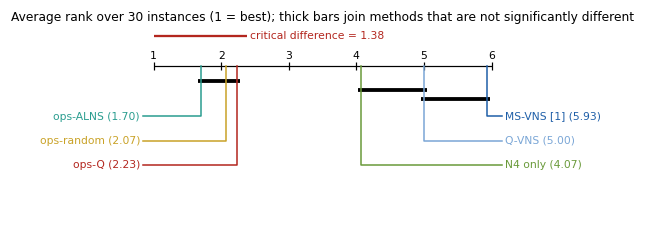

In [17]:
ranks, cd = Vz.plot_cd_diagram(res2); plt.show()

**Six criteria at once.** Each axis is scaled so that 1 is the best method on that criterion. The portfolio methods dominate on quality, vehicles, distance, estimated emissions and anytime quality; among them, ops-Q's weak spot is robustness (the largest spread across seeds), the price of its online learning. The MS-VNS of [1] is worst on every criterion, so its polygon collapses to the centre.

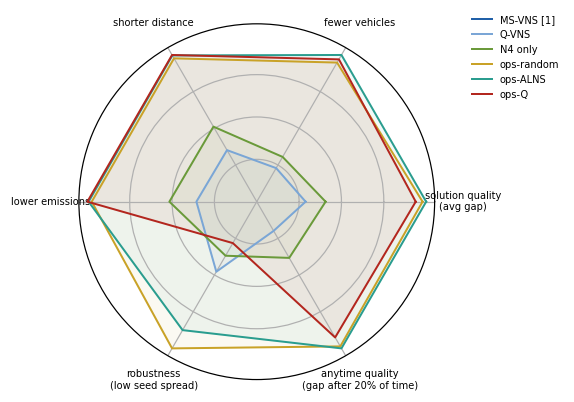

In [18]:
Vz.plot_radar(res2, conv2); plt.show()

### 6.2 Anatomy of a solution: [1]'s MS-VNS vs. ours
Same instance, same seed, same 60 s. Left: routes coloured by vehicle type, with one ■ per frigobox. Right: the load of every route as a share of its vehicle, split into fresh, frozen, unused frigobox space and empty space. The bulkhead of a mixed vehicle is the black tick. The portfolio packs vehicles fuller and uses fewer of them; the frigoboxes let fresh and frozen vehicles carry the other product.

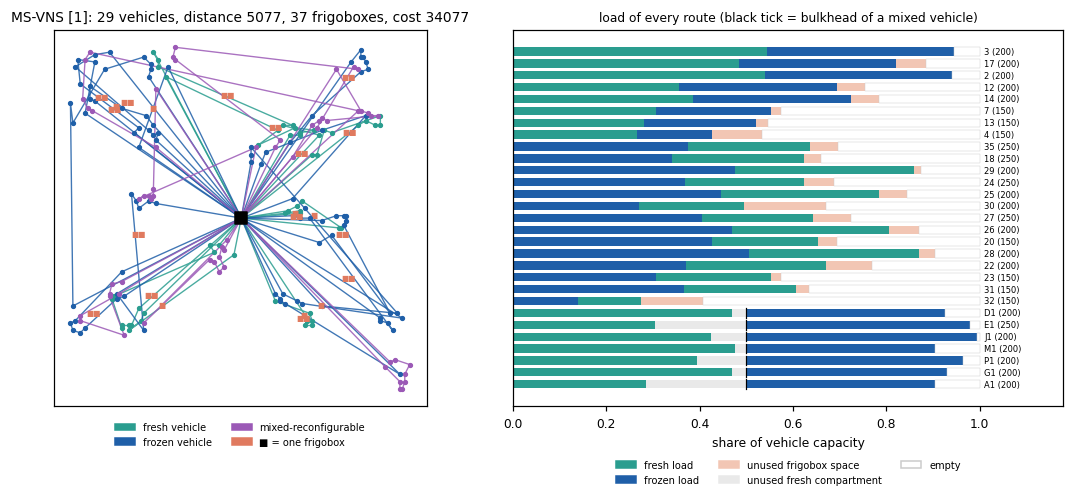

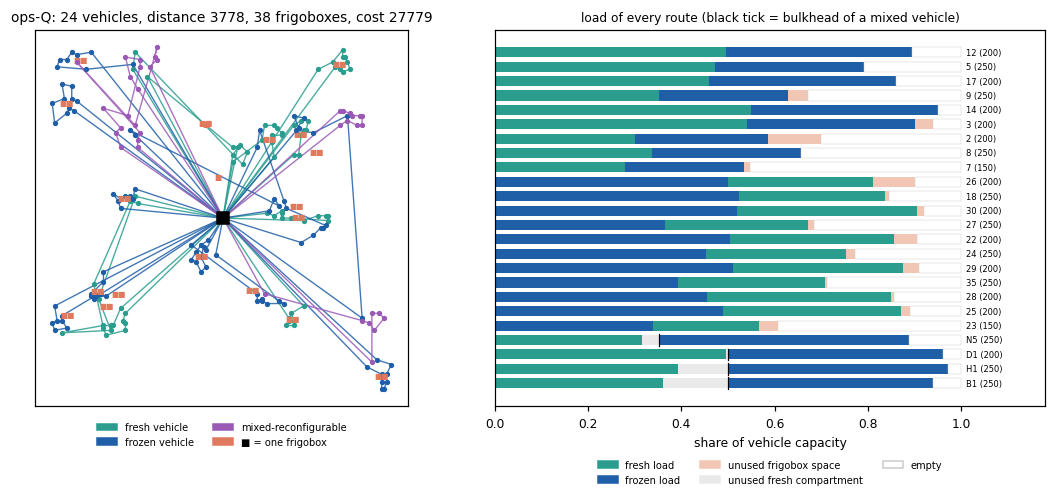

In [19]:
for alg in ["ms-vns", "ops-q"]:
    run_ = next(r for r in runs2 if r["instance"] == "A0-50-C121" and r["algorithm"] == alg and r["seed"] == 1)
    ev_ = Evaluator(inst)
    sol_ = Vz.solution_from_run(inst, run_, ev_)
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), gridspec_kw={"width_ratios": [1, 1.1]})
    Vz.plot_solution_anatomy(inst, sol_, ev_, axes,
        title=f"{Vz.SHORT[alg]}: {run_['vehicles']} vehicles, distance {run_['distance']:.0f}, "
              f"{run_['boxes']} frigoboxes, cost {run_['best_cost']:.0f}")
    plt.tight_layout(); plt.show()

### 6.3 Which operators are used, and how often do they fail?

algorithm,ops-alns,ops-q,ops-random
operator,,,
random+greedy,0.117,0.118,0.125
random+regret2,0.154,0.206,0.126
related+greedy,0.115,0.111,0.124
related+regret2,0.154,0.186,0.125
route+greedy,0.097,0.063,0.125
route+regret2,0.106,0.066,0.125
worst+greedy,0.106,0.082,0.125
worst+regret2,0.151,0.167,0.125


algorithm,ops-alns,ops-q,ops-random
operator,,,
random+greedy,19.4,9.1,20.9
random+regret2,0.6,0.5,0.5
related+greedy,19.5,9.3,21.2
related+regret2,1.7,1.7,1.2
route+greedy,41.7,40.9,45.6
route+regret2,36.3,39.4,39.4
worst+greedy,24.1,16.8,30.4
worst+regret2,5.0,8.0,3.8


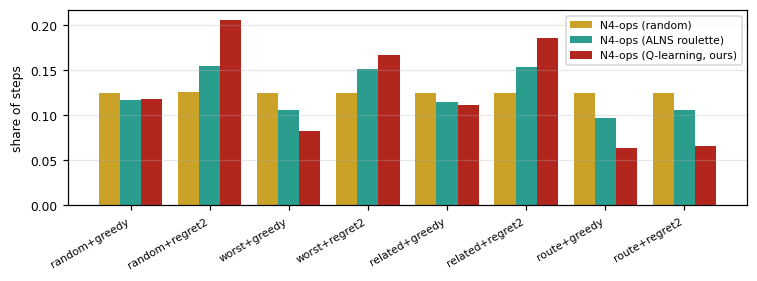

In [20]:
use2 = A.neighborhood_usage([r for r in runs2 if r["algorithm"] in OPS_ALGORITHMS])
use2["operator"] = use2["neighborhood"].str[1:].astype(int).map(lambda h: OP_NAMES[h - 1])
tab = use2.groupby(["algorithm", "operator"]).agg(share=("share", "mean"), picks=("picks", "sum"),
                                                  infeasible=("infeasible", "sum"))
tab["infeasible_%"] = (100 * tab["infeasible"] / tab["picks"]).round(1)
display(tab["share"].unstack(0).round(3))
display(tab["infeasible_%"].unstack(0))
algs = [a for a in OPS_ALGORITHMS if a in tab.index.get_level_values(0)]
fig, ax = plt.subplots(figsize=(7, 2.6)); w = 0.8 / max(1, len(algs))
for k, a in enumerate(algs):
    sh = tab.loc[a, "share"].reindex(OP_NAMES).fillna(0)
    ax.bar(np.arange(len(OP_NAMES)) + k * w, sh.values, w, color=P.COLORS.get(a), label=A.ALG_LABEL.get(a, a))
ax.set_xticks(np.arange(len(OP_NAMES)) + 0.4 - w / 2)
ax.set_xticklabels(OP_NAMES, rotation=30, ha="right", fontsize=7)
ax.set_ylabel("share of steps"); ax.legend(fontsize=7); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

**What did the agent learn?** Final Q-values of one run (rows: visited states, encoded as last outcome, stagnation, phase).

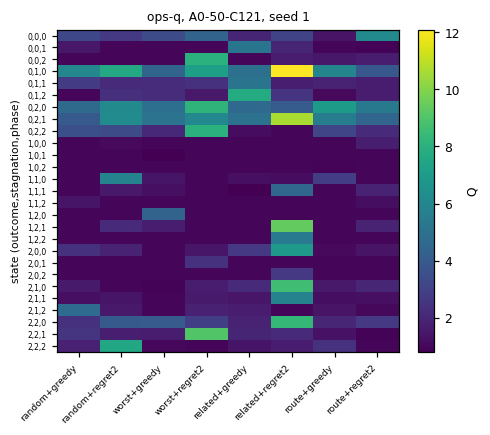

In [21]:
qrun = next(r for r in runs2 if r["algorithm"] == "ops-q")
fig, ax = plt.subplots(figsize=(4.5, 4))
P.plot_q_policy(qrun["selector_stats"]["q_table"], ax=ax, features=("outcome", "stagnation", "phase"))
ax.set_xticks(range(len(OP_NAMES))); ax.set_xticklabels(OP_NAMES, rotation=45, ha="right", fontsize=6)
ax.set_title(f'ops-q, {qrun["instance"]}, seed {qrun["seed"]}', fontsize=8); plt.tight_layout(); plt.show()

### 6.4 Learning dynamics: roulette wheel vs. Q-learning
**ALNS roulette** (stored run): the selection probabilities drift slowly and stay spread over all eight pairs, so every operator keeps being tried.

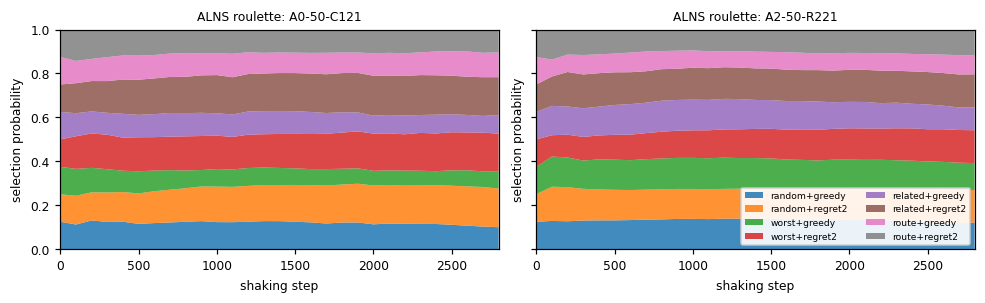

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(9, 2.8), sharey=True)
for ax, name in zip(axes, ["A0-50-C121", "A2-50-R221"]):
    ra = next(r for r in runs2 if r["instance"] == name and r["algorithm"] == "ops-alns" and r["seed"] == 1)
    Vz.plot_alns_weights(ra, OP_NAMES, ax=ax)
axes[1].legend(fontsize=6, ncol=2, loc="lower right", framealpha=0.9)
plt.tight_layout(); plt.show()

**Q-learning, recorded live** (30 s per instance; this cell runs the search and logs every decision). Compared with the roulette wheel, the agent commits much more strongly to a few pairs and changes its preference during the run. Watch the two `route` pairs (grey and pink): over all stored A1/A2 runs the agent gave them only 9% of its steps (Section 6.3), which is what costs it vehicles there. Section 7 confirms the cause. The run is random, so the exact picture changes from run to run.

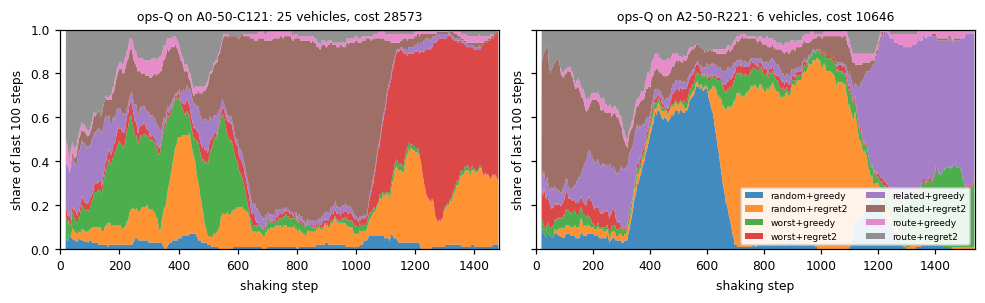

In [23]:
TRACE_SECONDS = 30
fig, axes = plt.subplots(1, 2, figsize=(9, 2.8), sharey=True)
for ax, name in zip(axes, ["A0-50-C121", "A2-50-R221"]):
    I_ = load_instance(f"{DATA}/Instances/200 customers/{name}.txt")
    res_, trace = Vz.trace_run(I_, "ops-q", TRACE_SECONDS, seed=1)
    Vz.plot_learning_trace(trace, OP_NAMES, ax=ax, window=100,
                           title=f"ops-Q on {name}: {res_.vehicles} vehicles, cost {res_.best_cost:.0f}")
axes[1].legend(fontsize=6, ncol=2, loc="lower right", framealpha=0.9)
plt.tight_layout(); plt.show()

## 7. Parameter sensitivity of the Q-learning policy
One parameter at a time is changed around the default ($\alpha=0.1$, $\gamma=0.9$, $\varepsilon_0=0.3$, rewards $(5,2,0.5,0,-1)$), on 6 instances (one per family) × 3 seeds × 60 s, giving 8 variants and 144 runs (stored in `results/sens`, produced on the same MacBook with `--workers 3`). The default and the reference selectors come from the main experiment (same instances and seeds). The last column gives the share of route-removal steps on A1/A2, the operator that the reward design affects most (Section 6).

In [24]:
RUN_SENS = False
SENS_DIR = f"{RESULTS_ROOT}/sens"
SENS_INSTANCES = "A0-50-C121 A0-50-R121 A0-50-RC121 A1-50-C221 A2-50-R221 A2-50-RC221"
SENS_VARIANTS = ["alpha=0.05", "alpha=0.3", "gamma=0.5", "gamma=0.99",
                 "eps_start=0.1", "eps_start=0.5", "rewards=[1,0,0,0,0]", "rewards=[5,2,0.5,0,0]"]
if RUN_SENS:
    for qarg in SENS_VARIANTS:
        label = f"ops-q@{qarg}"
        !python experiments/run.py --data $DATA --instances $SENS_INSTANCES --algorithms ops-q \
            --q "$qarg" --label "$label" --seeds 1-3 --time-limit 60 --workers 2 --out "$SENS_DIR"

results from: results/sens


,runs,gap_all,gap_A0,gap_A1A2,veh_A1A2,route_share_A1A2_%
algorithm,,,,,,
ops-ALNS (reference),18,-16.97,-12.13,-21.81,6.67,19.79
alpha=0.3,18,-16.75,-13.14,-20.35,6.78,11.94
ops-random (reference),18,-16.12,-10.47,-21.77,6.67,25.34
gamma=0.5,18,-16.04,-13.18,-18.91,7.00,6.64
default,18,-15.99,-12.66,-19.31,7.00,7.46
"rewards=[5,2,0.5,0,0]",18,-15.88,-11.96,-19.79,6.78,18.84
eps_start=0.5,18,-15.76,-12.57,-18.94,7.11,10.12
"rewards=[1,0,0,0,0]",18,-15.66,-10.26,-21.06,6.67,27.20
alpha=0.05,18,-14.89,-11.89,-17.89,7.11,8.00


Wilcoxon p vs default: {'alpha=0.05': 0.012, 'alpha=0.3': 0.154, 'eps_start=0.1': 0.284, 'eps_start=0.5': 0.671, 'gamma=0.5': 0.865, 'gamma=0.99': 0.061, 'rewards=[1,0,0,0,0]': 0.284, 'rewards=[5,2,0.5,0,0]': 0.535}


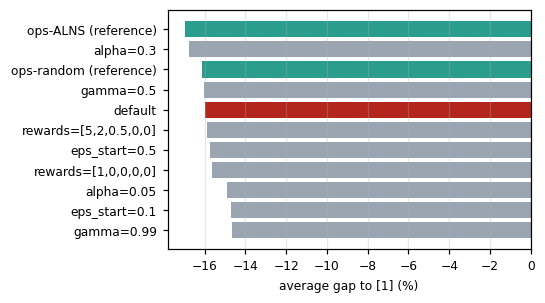

In [25]:
SENS = results_dir(SENS_DIR, "results/sens")
names = SENS_INSTANCES.split()
sens = A.add_gaps(A.load_results(SENS), refs)
ref_runs = res2[res2["algorithm"].isin(["ops-q", "ops-alns", "ops-random"]) & res2["instance"].isin(names)
                & res2["seed"].isin([1, 2, 3])]
ref_runs = ref_runs.assign(algorithm=ref_runs["algorithm"].map(
    {"ops-q": "ops-q@default", "ops-alns": "ops-ALNS (reference)", "ops-random": "ops-random (reference)"}))
allv = pd.concat([ref_runs, sens], ignore_index=True)
allv["cls"] = np.where(allv["instance"].str.startswith("A0"), "A0", "A1/A2")
stab = allv.groupby("algorithm").agg(runs=("gap", "size"), gap_all=("gap", "mean"))
stab["gap_A0"] = allv[allv["cls"] == "A0"].groupby("algorithm")["gap"].mean()
stab["gap_A1A2"] = allv[allv["cls"] == "A1/A2"].groupby("algorithm")["gap"].mean()
stab["veh_A1A2"] = allv[allv["cls"] == "A1/A2"].groupby("algorithm")["vehicles"].mean()
sel_runs = A.load_runs(SENS) + [r for r in runs2 if r["algorithm"] in ("ops-q", "ops-alns", "ops-random")
                                and r["instance"] in names and r["seed"] <= 3]
us = A.neighborhood_usage(sel_runs)
us = us[~us["instance"].str.startswith("A0") & us["neighborhood"].isin(["N7", "N8"])]  # route+greedy, route+regret2
route = us.groupby(["algorithm", "instance", "seed"])["share"].sum().groupby("algorithm").mean()
ren = {"ops-q": "ops-q@default", "ops-alns": "ops-ALNS (reference)", "ops-random": "ops-random (reference)"}
route.index = [ren.get(i, i) for i in route.index]
stab["route_share_A1A2_%"] = (100 * route).reindex(stab.index)
stab.index = stab.index.str.replace("ops-q@", "", regex=False)
display(stab.sort_values("gap_all").round(2))
# paired Wilcoxon of each variant against the default (18 instance-seed pairs)
from scipy.stats import wilcoxon
piv = allv.pivot_table(index=["instance", "seed"], columns="algorithm", values="best_cost")
pv = {c.replace("ops-q@", ""): wilcoxon(piv[c], piv["ops-q@default"]).pvalue
      for c in piv.columns if c.startswith("ops-q@") and c != "ops-q@default"}
print("Wilcoxon p vs default:", {k: round(float(v), 3) for k, v in pv.items()})
s_ = stab.sort_values("gap_all")
fig, ax = plt.subplots(figsize=(5, 2.8))
ax.barh(s_.index, s_["gap_all"], color=["#b3261e" if i == "default" else ("#2a9d8f" if "reference" in i else "#9aa5b1")
                                        for i in s_.index])
ax.set_xlabel("average gap to [1] (%)"); ax.invert_yaxis(); ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.show()

## 8. Small instances: comparison with CPLEX
In [1], CPLEX (4 h limit) solved all 10-customer instances, and the authors report these solutions as optimal; the published solutions equal them. A gap of 0 therefore means the reported CPLEX value was matched (5 s per run).

In [26]:
small = []
for p in list_instances(DATA, "10 customers"):
    I = load_instance(p)
    for alg in ["ms-vns", "ops-q"]:
        r = run(I, alg, 5)
        small.append({"instance": I.name, "algorithm": alg, "best_cost": r.best_cost, "feasible": r.feasible})
small = pd.DataFrame(small).merge(refs[["instance", "ref_cost"]], on="instance", how="left")
small["gap"] = 100 * (small["best_cost"] - small["ref_cost"]) / small["ref_cost"]
small.pivot(index="instance", columns="algorithm", values="gap").round(3)

algorithm,ms-vns,ops-q
instance,,
A0-10-C121,-0.000,-0.000
A0-10-C123,-0.000,0.012
A0-10-C124,-0.000,-0.000
A0-10-C127,NaN,NaN
A0-10-C129,0.008,0.008
A0-10-R121,0.000,0.000
A0-10-R1210,-0.000,-0.000
A0-10-R122,0.009,0.009
A0-10-R126,-0.008,-0.008


## 9. Interactive explorer
Pick any of the 900 stored solutions (instance, method, seed) to see its routes, vehicle types, frigoboxes and loads. The dropdowns need a live session (Colab or Jupyter); on GitHub only the first view is shown.

In [27]:
Vz.explorer(runs2, DATA, refs)

Output()

## 10. Pros and cons
**Operator portfolio (Experiment 2).**
* Pro: regret-2 insertion and route removal attack the vehicle term of $f(x)$. All three portfolio methods end 12.5–13.6% below the published solutions with about 2.4 fewer vehicles than MS-VNS, and beat MS-VNS, Q-VNS and $N_4$ only on all 30 instances (Section 6).
* Con: destroy-and-repair steps are expensive, so only about 136 restarts fit in 60 s, against 423 for MS-VNS.

**Learned selection (Q-learning) vs. ALNS roulette vs. random.**
* Pro: Q-learning conditions its choice on the search state, needs no hand-set weights, and is the best selector on the small-vehicle (A0) instances, where avoiding failing greedy insertions matters.
* Con: it is only as good as its reward. The per-step reward penalizes failure and ignores the size of a gain, so on large-vehicle (A1/A2) instances it avoids route removal, the operator that closes routes, and loses to both rivals. Overall it does not beat the roulette wheel ($p=0.15$) and has twice its seed-to-seed spread. Section 7 confirms the mechanism: removing the penalty raises route removal and improves A1/A2 but hurts A0.

**Implementation.** Python is 10–50 times slower than the C++ code of [1]. All methods therefore share the same wall-clock budget and machine, and gaps to [1] are reported for reference only.